# DAY 4 — MINI PROJECT: DOG VS CAT CLASSIFIER

## Objective

Build a basic image classification system that can distinguish between:

- Dog
- Cat

This project applies the CNN concepts learned on Day 3.

## Project Pipeline
```text
Dog/Cat Images
↓
Data Cleaning
↓
Resize Images
↓
Normalize
↓
Train / Validation Split
↓
CNN
↓
Training
↓
Evaluation
↓
Dog or Cat
```
## Topics Covered

1. Image classification
2. Dataset organization
3. Data cleaning
4. Image loading
5. Image resizing
6. Image normalization
7. Train / validation split
8. CNN model
9. Model training
10. Model evaluation
11. Prediction
12. Dog vs Cat classification

# 1. What is Image Classification?

Image classification is the process of assigning an image to one of a predefined set of classes.

For this project, we have two classes:

```text
Class 0 → Cat
Class 1 → Dog
```
The model receives an image:
```text
Image
  ↓
CNN
  ↓
Probability
  ↓
Class
```
### Example:

Cat probability = 0.91
Dog probability = 0.09

The model predicts:

#### CAT

### Another example:

Cat probability = 0.12
Dog probability = 0.88

The model predicts:

#### DOG

# 2. Dataset Organization

For image classification, it is useful to organize images according to their class.

A simple directory structure is:

```text
dataset/
│
├── cat/
│   ├── cat001.jpg
│   ├── cat002.jpg
│   ├── cat003.jpg
│   └── ...
│
└── dog/
    ├── dog001.jpg
    ├── dog002.jpg
    ├── dog003.jpg
    └── ...
```
The folder names represent the class labels.

Therefore:

cat folder → Cat

dog folder → Dog

The image files inside each folder are the examples used to train the model.

# 3. Data Cleaning

Before training a CNN, the image dataset should be checked.

Possible problems include:

- Corrupted images
- Unsupported file formats
- Missing images
- Incorrect labels
- Extremely unusual image files
- Duplicate images

Data cleaning helps ensure that the model receives valid training data.

A simplified workflow is:
```text 
Raw Dataset
↓
Check Images
↓
Remove Invalid Images
↓
Correct Dataset
↓
Continue Processing

# 4. Checking Image Files

Common image formats include:

- JPG
- JPEG
- PNG
- BMP

For this project, we can identify files using their extensions.

Only valid image files should be passed to the image-processing pipeline.

The exact cleaning process depends on the dataset being used.

# 5. Resizing Images

Images can have different dimensions.

For example:

```text
Image 1 → 500 × 400
Image 2 → 800 × 600
Image 3 → 300 × 300
```
A CNN normally expects a consistent input shape.

Therefore, images are resized to a common size.

#### For example:

128 × 128 × 3

#### This means:

Height = 128
Width = 128
RGB channels = 3

#### The process is:
```text
Original Image
      ↓
Resize
      ↓
128 × 128 × 3

In [4]:
import sys

print(sys.executable)

c:\Users\LENOVO\miniconda3\envs\week4_dl\python.exe


In [5]:
import sys
!{sys.executable} -m pip install pillow

In [6]:
from PIL import Image
import numpy as np

# Create an example image
image = Image.new("RGB", (300, 200))

print("Original size:", image.size)

# Resize
resized_image = image.resize((128, 128))

print("Resized size:", resized_image.size)

Original size: (300, 200)
Resized size: (128, 128)


# 6. Normalizing Images

Image pixels are commonly represented using values between:

```text
0 and 255
```
### For example:
```text
0   → Black
255 → Maximum intensity
```
Neural networks often work better when input values are scaled to a smaller range.

### A common approach is:

normalized_pixel = pixel / 255

#### Therefore:
```text
0   → 0.0
128 → 0.502
255 → 1.0
```
This converts pixel values approximately into the range:

0 to 1

### The process becomes:
```text
Original Pixel
     ↓
Divide by 255
     ↓
Normalized Pixel

In [7]:
pixels = np.array([0, 64, 128, 192, 255])

normalized = pixels / 255.0

print("Original pixels:")
print(pixels)

print("\nNormalized pixels:")
print(normalized)

Original pixels:
[  0  64 128 192 255]

Normalized pixels:
[0.         0.25098039 0.50196078 0.75294118 1.        ]


# 7. Loading the Dataset

TensorFlow/Keras provides utilities for loading images from directories.

When using a directory-based dataset:

```text
cat/
dog/
```
the directory names can be used as class labels.

#### The loader can:
```text
Read the images.
Resize them.
Group them into batches.
Assign labels.
Prepare them for the CNN.

This greatly simplifies the image-data pipeline.

# 8. Train / Validation Split

We should not train and evaluate the model using exactly the same images.

Therefore, the dataset is divided into separate subsets.

### Training Dataset

Used to learn the model's parameters.

### Validation Dataset

Used to evaluate the model during training on images that were not used to update the model's parameters.

A common split is:

```text
80% → Training
20% → Validation


The exact ratio can vary depending on the dataset.

The basic flow is:

Complete Dataset
       ↓
 ┌─────┴─────┐
 ↓           ↓
Training   Validation
 80%          20%

# 9. Creating Training and Validation Datasets

We can use TensorFlow's `image_dataset_from_directory()` to load images from the class folders.

Example directory:

```text
dataset/
├── cat/
└── dog/
```
### The function can automatically:
```text
Load the images
Resize them
Create batches
Assign labels
Split the dataset into training and validation sets

In [8]:
import tensorflow as tf

DATASET_DIR = "dataset"

IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32

train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

print("Classes:", train_dataset.class_names)

Found 1000 files belonging to 2 classes.
Using 800 files for training.
Found 1000 files belonging to 2 classes.
Using 200 files for validation.
Classes: ['cat', 'dog']


# 10. Understanding Class Labels

The dataset loader assigns numerical labels to the classes.

For example:

```text
0 → cat
1 → dog
```
The exact mapping should always be checked using:
```python
train_dataset.class_names
```
For a binary classification problem, the model eventually produces a value representing the probability of one class.

For example:

0.10 → likely Cat
0.90 → likely Dog

The exact interpretation depends on the class ordering used by the dataset.

# 11. Normalizing the Dataset

The images loaded by TensorFlow contain pixel values.

We can normalize them using:

```text
pixel / 255
```
TensorFlow provides a preprocessing layer for this:
```python
tf.keras.layers.Rescaling(1./255)
```
This can be placed inside the model.

#### Advantages:
```text
Keeps preprocessing together with the model.
Ensures the same scaling is used during training and prediction.
Makes the input values approximately range from 0 to 1.

In [9]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

normalized_train_dataset = train_dataset.map(
    lambda images, labels: (normalization_layer(images), labels)
)

normalized_validation_dataset = validation_dataset.map(
    lambda images, labels: (normalization_layer(images), labels)
)

print("Normalization completed.")

Normalization completed.


# 12. Viewing Sample Images

Before training the model, it is useful to inspect some images from the dataset.

This helps us verify:

- Images are loading correctly.
- Images have the expected dimensions.
- Labels are being assigned.
- The dataset appears reasonable.

In [10]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


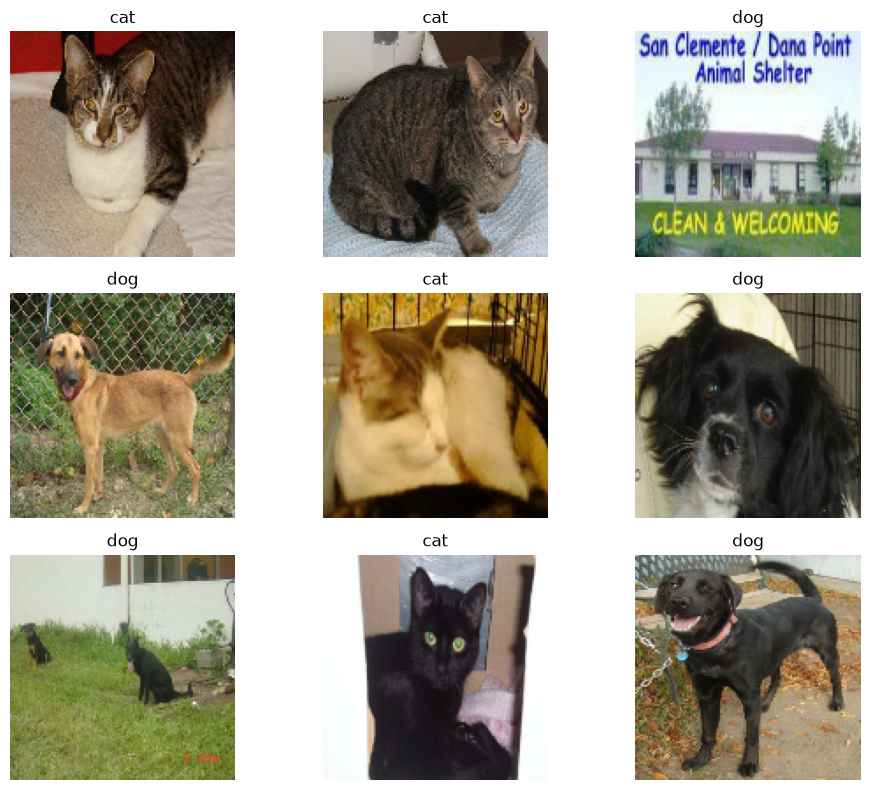

In [12]:
import matplotlib.pyplot as plt

class_names = train_dataset.class_names

plt.figure(figsize=(10, 8))

for images, labels in train_dataset.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i].numpy()[0])
        plt.title(class_names[label])

        plt.axis("off")

plt.tight_layout()
plt.show()

# 13. Creating the CNN Model

Now we create the CNN that will learn to classify the images.

Our architecture will be:

```text
Input Image
     ↓
Rescaling
     ↓
Conv2D
     ↓
ReLU
     ↓
MaxPooling
     ↓
Conv2D
     ↓
ReLU
     ↓
MaxPooling
     ↓
Conv2D
     ↓
ReLU
     ↓
MaxPooling
     ↓
Flatten
     ↓
Dense
     ↓
Output
```
Because this is a binary classification problem, the final layer can contain one neuron with a sigmoid activation.

In [ ]:
model = tf.keras.Sequential([
    
    tf.keras.layers.Input(shape=(128, 128, 3)),

    # Normalize pixel values
    tf.keras.layers.Rescaling(1./255),

    # Convolution Block 1
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),

    # Binary output
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_4 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

 # 14. Understanding the CNN Model

## Input

```text
128 × 128 × 3
```
The model receives an RGB image.

Rescaling
Pixel / 255

Converts the pixel values approximately from:

0–255

to:

0–1
### First Convolution
32 filters
3 × 3 kernel

Learns basic visual patterns.

### First Max Pooling

Reduces the spatial dimensions.

### Second Convolution

Uses 64 filters.

This deeper layer can learn more complex patterns.

### Third Convolution

Uses 128 filters.

Deeper layers can learn increasingly complex visual representations.

### Flatten

Converts the final feature maps into a one-dimensional vector.

### Dense Layer

Processes the learned visual features.

### Final Output
```python
Dense(1, activation="sigmoid")
```
Because this is binary classification, one output value is sufficient.

The sigmoid output represents a value between 0 and 1.

# 15. Compiling the CNN

Before training, we compile the model.

We need:

### Optimizer

Controls how the model's parameters are updated.

We will use:

```text
Adam
```
### Loss Function

For binary classification, we use:
```python
Binary Cross-Entropy
```
### Metric

We will track:
```python
Accuracy

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


# 16. Training the CNN

During training, the CNN repeatedly:

1. Receives training images.
2. Performs forward propagation.
3. Produces predictions.
4. Calculates the loss.
5. Performs backpropagation.
6. Calculates gradients.
7. Updates the model parameters.
8. Repeats the process.

The validation dataset is evaluated after training batches to monitor how the model performs on held-out data.

The number of complete passes through the training dataset is controlled by the number of epochs.

In [ ]:
EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS
)

Epoch 1/10


c:\Users\LENOVO\miniconda3\envs\week4_dl\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


25/25 ━━━━━━━━━━━━━━━━━━━━ 18s 597ms/step - accuracy: 0.5288 - loss: 0.7652 - val_accuracy: 0.5700 - val_loss: 0.6798
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 11s 426ms/step - accuracy: 0.5200 - loss: 0.6905 - val_accuracy: 0.5700 - val_loss: 0.6774
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 11s 426ms/step - accuracy: 0.5238 - loss: 0.6880 - val_accuracy: 0.5700 - val_loss: 0.6772
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 11s 424ms/step - accuracy: 0.5525 - loss: 0.6718 - val_accuracy: 0.4350 - val_loss: 0.7070
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 11s 423ms/step - accuracy: 0.5850 - loss: 0.6570 - val_accuracy: 0.5950 - val_loss: 0.6660
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 14s 563ms/step - accuracy: 0.6662 - loss: 0.5991 - val_accuracy: 0.6100 - val_loss: 0.6678
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 18s 431ms/step - accuracy: 0.7538 - loss: 0.5125 - val_accuracy: 0.6350 - val_loss: 0.6613
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 11s 425ms/step - accuracy: 0.7725 - loss: 0.4530 - val_accuracy: 0.670

# 17. Understanding Training Results

During training, we can observe:

- Training loss
- Training accuracy
- Validation loss
- Validation accuracy

### Training Accuracy

Shows how accurately the model classifies the training images.

### Validation Accuracy

Shows how accurately the model classifies the validation images.

### Training Loss

Measures the model's error on training data.

### Validation Loss

Measures the model's error on validation data.

We compare training and validation performance to understand how well the model is generalizing.

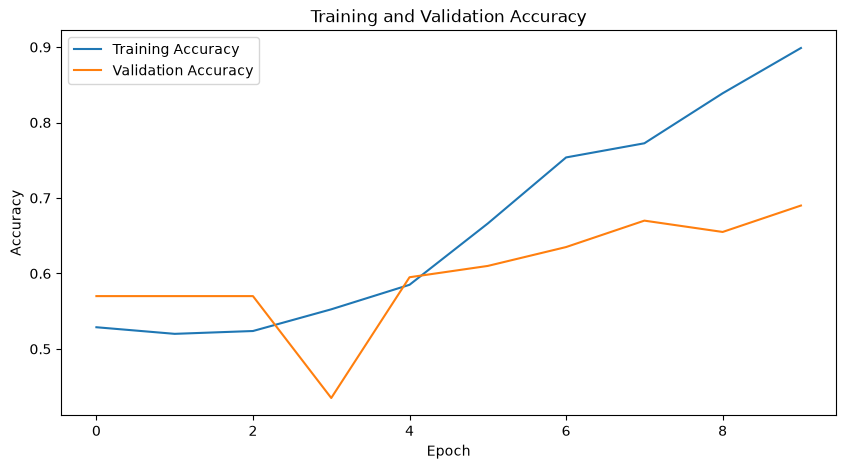

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# 18. Evaluating the Model

After training, we evaluate the CNN using the validation dataset.

Evaluation helps us understand how well the trained model performs on images that were not directly used to update its parameters.

We can measure:

- Loss
- Accuracy

In [ ]:
validation_loss, validation_accuracy = model.evaluate(
    validation_dataset,
    verbose=1
)

print("\nValidation Loss:", validation_loss)
print("Validation Accuracy:", validation_accuracy)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - accuracy: 0.6900 - loss: 0.8977

Validation Loss: 0.8976628184318542
Validation Accuracy: 0.6899999976158142


# 19. Making a Prediction

Once the model has been trained, we can give it a new image.

The model produces a probability.

For example:

```text
0.92
```
For a binary classifier, this value can be converted into a class using a threshold.

For example, using a threshold of 0.5:

probability >= 0.5 → Dog
probability < 0.5  → Cat

The exact class mapping depends on the dataset's class order.

Always check:
```python
train_dataset.class_names

In [ ]:
# 21. PREDICT A SINGLE IMAGE
def predict_image(image_path):
    image = tf.keras.utils.load_img(
        image_path,
        target_size=(128, 128)
    )

    image_array = tf.keras.utils.img_to_array(image)

    image_array = tf.expand_dims(image_array, 0)

    probability = model.predict(image_array, verbose=0)[0][0]

    class_names = train_dataset.class_names

    if probability >= 0.5:
        predicted_class = class_names[1]
        confidence = probability
    else:
        predicted_class = class_names[0]
        confidence = 1 - probability

    print("Predicted class:", predicted_class)
    print("Confidence:", round(float(confidence) * 100, 2), "%")

In [ ]:
# Replace this with the path of a test image

test_image_path = "test_image.jpg"

predict_image(test_image_path)

Predicted class: cat
Confidence: 73.89 %


# 20. Complete Dog vs Cat Classifier Pipeline

The complete project pipeline is:

```text
             DOG / CAT IMAGES
                     ↓
               DATA CLEANING
                     ↓
              IMAGE LOADING
                     ↓
              RESIZE IMAGES
                     ↓
                NORMALIZE
                     ↓
          TRAIN / VALIDATION SPLIT
                ↓           ↓
            TRAINING     VALIDATION
                ↓           ↓
                 └─────┬─────┘
                       ↓
                      CNN
                       ↓
                   TRAINING
                       ↓
                  EVALUATION
                       ↓
                  NEW IMAGE
                       ↓
                  PREDICTION
                       ↓
                  DOG OR CAT

# 21. How the CNN Identifies Dog vs Cat

Suppose the input image is a cat.

The process is:

### Step 1 — Input

The image is resized to the expected dimensions.

### Step 2 — Normalization

Pixel values are scaled to approximately 0–1.

### Step 3 — Convolution

The CNN detects visual patterns.

Early layers may learn:

- Edges
- Lines
- Corners

### Step 4 — Deeper Convolution

Deeper layers can learn:

- Textures
- Shapes
- Curves
- Fur patterns
- Facial structures

### Step 5 — Pooling

Important activations are retained while spatial dimensions are reduced.

### Step 6 — Flatten

The feature maps are converted into a one-dimensional representation.

### Step 7 — Dense Layer

The learned features are combined for classification.

### Step 8 — Sigmoid

The output is converted into a value between 0 and 1.

### Step 9 — Classification

The value is interpreted according to the class mapping.

Example:

```text
Cat = 0.93
Dog = 0.07

# 22. Classification Threshold

The model's sigmoid output is a probability-like value between 0 and 1.

To convert it into a class, we use a threshold.

For example:

```text
Threshold = 0.5
```
If the output is:

0.80

then:

0.80 >= 0.50

The model chooses the positive class.

If the output is:

0.20

then:

0.20 < 0.50

The model chooses the other class.

The threshold can be changed depending on the application and desired trade-off between different classification errors.

For this basic project, we use 0.5 as the default threshold.

# 23. Day 4 — Important Terms

| Term | Meaning |
|---|---|
| Image Classification | Assigning an image to a predefined class |
| Dataset | Collection of training and validation images |
| Data Cleaning | Removing or handling invalid data |
| Resize | Converting images to a consistent size |
| Normalization | Scaling pixel values to a smaller range |
| Training Set | Data used to learn model parameters |
| Validation Set | Held-out data used to monitor model performance |
| CNN | Neural network designed for image-related tasks |
| Convolution | Operation used to detect visual patterns |
| Pooling | Reduces spatial dimensions |
| Flatten | Converts feature maps into a vector |
| Dense | Fully connected neural network layer |
| Sigmoid | Produces an output between 0 and 1 |
| Threshold | Converts a probability-like output into a class |
| Epoch | One complete pass through training data |
| Accuracy | Percentage of correctly classified examples |